# Scoring du risque de défaut de crédit — analyse et modélisation (Home Credit)

**Problème :** estimer le risque de difficulté de remboursement à partir du jeu de données public **Home Credit Default Risk** (Kaggle).  
**Démarche :** données financières de base → historique des crédits externes → demandes précédentes → remboursements.  
**Modèle :** régression logistique interprétable, avec une comparaison explicite des pondérations de classes.  
**Protocole :** répartition fixe et stratifiée **60 % apprentissage / 20 % validation / 20 % test**, calcul des transformations sur l'apprentissage seulement, sélection sur validation et **une seule évaluation finale sur le test**.

**Fichiers nécessaires :** `application_train.csv`, `bureau.csv`, `previous_application.csv` et `installments_payments.csv`, à placer dans le **même dossier d'exécution** que le notebook (ou à adapter dans les chemins `pd.read_csv`).

> **Périmètre :** projet pédagogique, et non système de décision bancaire. L'exploitation de l'historique exige de vérifier la disponibilité des événements à la date de chaque demande et les biais éventuels, avant toute utilisation réelle.


# Première partie
### Exploration des données
#### Objectif : comprendre la structure du dataset

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [2]:
df = pd.read_csv('application_train.csv')
df.head()

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,...,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,...,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,...,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,...,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,...,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,...,0,0.0,0.0,0.0,0.0,0.0,0.0


In [3]:
(df.isna().mean() * 100).sort_values(ascending=False)

COMMONAREA_AVG              69.872297
COMMONAREA_MODE             69.872297
COMMONAREA_MEDI             69.872297
NONLIVINGAPARTMENTS_MEDI    69.432963
NONLIVINGAPARTMENTS_MODE    69.432963
                              ...    
FLAG_DOCUMENT_16             0.000000
FLAG_DOCUMENT_15             0.000000
FLAG_DOCUMENT_14             0.000000
FLAG_DOCUMENT_20             0.000000
FLAG_DOCUMENT_21             0.000000
Length: 122, dtype: float64

In [4]:
# Comptage des classes dans TARGET
target_counts = df['TARGET'].value_counts(normalize=True)
target_counts

TARGET
0    0.919271
1    0.080729
Name: proportion, dtype: float64

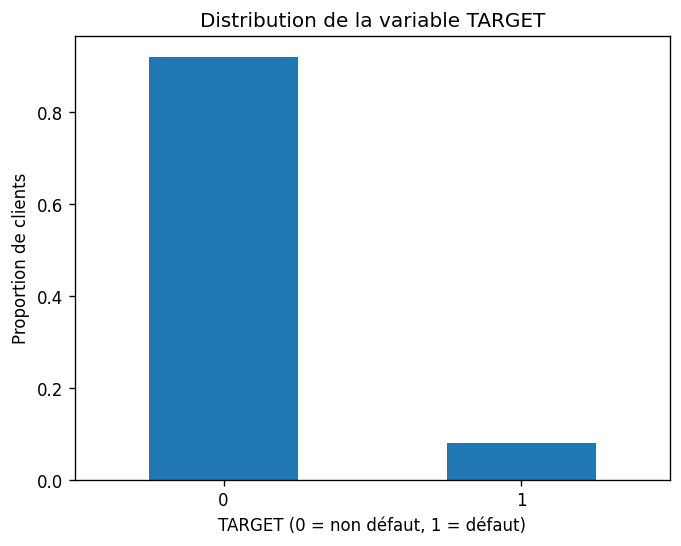

In [5]:
# Bar plot
target_counts.sort_index().plot(kind = 'bar')
plt.title('Distribution de la variable TARGET')
plt.xlabel('TARGET (0 = non défaut, 1 = défaut)')
plt.ylabel('Proportion de clients')
plt.xticks(rotation=0)
plt.show()

Les deux classes sont déséquilibrées (environ 8 % de défauts). Pour évaluer un modèle de scoring, on privilégiera notamment ROC-AUC et Average Precision, complétés par l'examen des erreurs de classification.

L'accuracy seule est peu informative ici : prédire systématiquement la classe majoritaire donnerait un score élevé sans détecter de défauts. De plus, les coûts d'un refus injustifié et d'un défaut non anticipé ne sont pas nécessairement égaux.

### Conclusion

Le déséquilibre des classes invite à une évaluation prudente. Les décisions opérationnelles (acceptation, refus, examen manuel) nécessiteraient des critères métier, une calibration et un cadre réglementaire adaptés ; elles ne sont pas déduites directement de cette analyse exploratoire.

# Deuxième partie
### Analyse et compréhension du risque

Différentes variables influes sur la définition du risque parmis lesquelles on retrouve : l'age, le revenu, ou encore le montant du crédit.
La première variable sur laquelle nous allons nous concentrer est la variable de l'âge. En effet, l'âge est fortement lié à la stabilité financière et au cycle de vie du client. Les profils plus jeunes peuvent représenter un risque de part une situation professionnelle encore instable tandis que les profils plus agés voient leur capacité de remboursement diminuer, notamment à l'approche de la retraite.

L’âge du client est calculé à partir de la variable DAYS_BIRTH, exprimée en nombre de jours avant la demande de crédit.

In [6]:
# Etude de l'âge du client
df['AGE'] = (-df['DAYS_BIRTH'] / 365).round(1)
df['AGE'].describe()

count    307511.000000
mean         43.936992
std          11.956084
min          20.500000
25%          34.000000
50%          43.200000
75%          53.900000
max          69.100000
Name: AGE, dtype: float64

Text(0.5, 1.0, "Distribution de l'âge des clients")

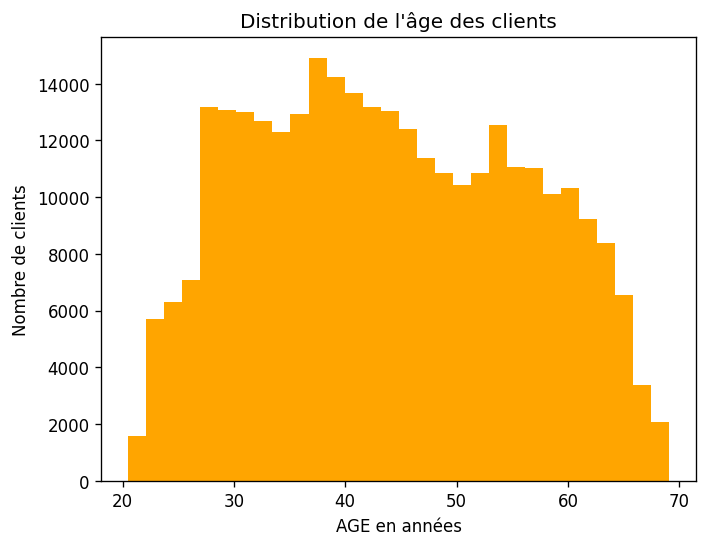

In [7]:
plt.hist(df['AGE'], bins = 30, color = 'orange')
plt.xlabel('AGE en années')
plt.ylabel('Nombre de clients')
plt.title("Distribution de l'âge des clients")

La disribution de l'âge montre un portefeuille principalement composé de personnes en âge d'activité, ce qui est cohérent avec notre problème.

In [8]:
# Voici la comparaison entre clients en défaut et non-défaut permet d’identifier des tranches d’âge associées à un risque plus élevé.

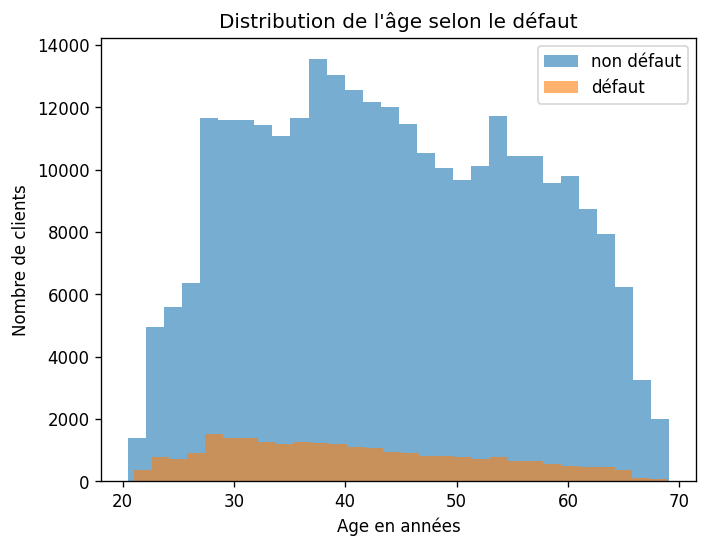

In [9]:
plt.hist(df[df['TARGET'] == 0]['AGE'], bins = 30, alpha = 0.6, label = 'non défaut')
plt.hist(df[df['TARGET'] == 1]['AGE'], bins = 30, alpha = 0.6, label = 'défaut')

plt.title("Distribution de l'âge selon le défaut")
plt.xlabel('Age en années')
plt.ylabel('Nombre de clients')
plt.legend()
plt.show()

Les défauts semblent davantage représentés chez les clients âgés de 25 à 40 ans.
Toutefois, cette observation doit être interprétée avec prudence, car elle peut refléter une plus forte concentration de clients dans cette tranche d’âge.
Aucun pic de risque net n’est observé, ce qui suggère que l’âge seul n’est pas un facteur discriminant suffisant.

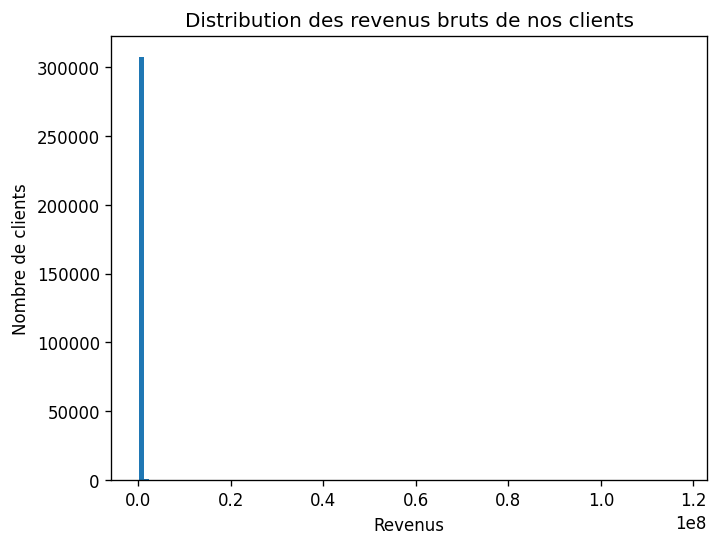

In [10]:
# Affichage de la distribution brute

plt.hist(df['AMT_INCOME_TOTAL'], bins = 100)
plt.title('Distribution des revenus bruts de nos clients')
plt.xlabel('Revenus')
plt.ylabel('Nombre de clients')
plt.show()

La distribution des revenus est fortement asymétrique, avec quelques valeurs extrêmement élevées.
Une transformation logarithmique est donc utilisée afin de rendre la distribution lisible et exploitable lors de l’analyse exploratoire

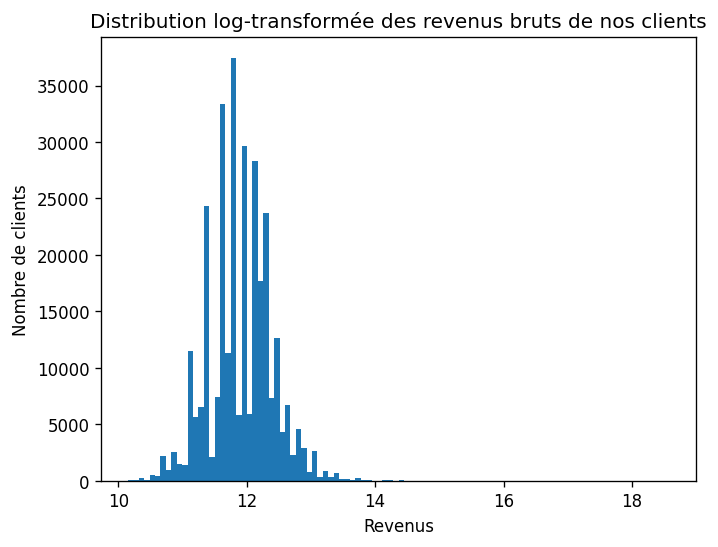

In [11]:
# Passage au logarithme pour réduire l'asymétrie de la distribution et la rendre plus lisible

plt.hist(np.log1p(df['AMT_INCOME_TOTAL']), bins = 100)
plt.title('Distribution log-transformée des revenus bruts de nos clients')
plt.xlabel('Revenus')
plt.ylabel('Nombre de clients')
plt.show()

La majorité des clients se situe dans une tranche de revenus intermédiaires, avec une dispersion modérée. Les très hauts revenus sont rares et constituent des cas particuliers à analyser séparément.

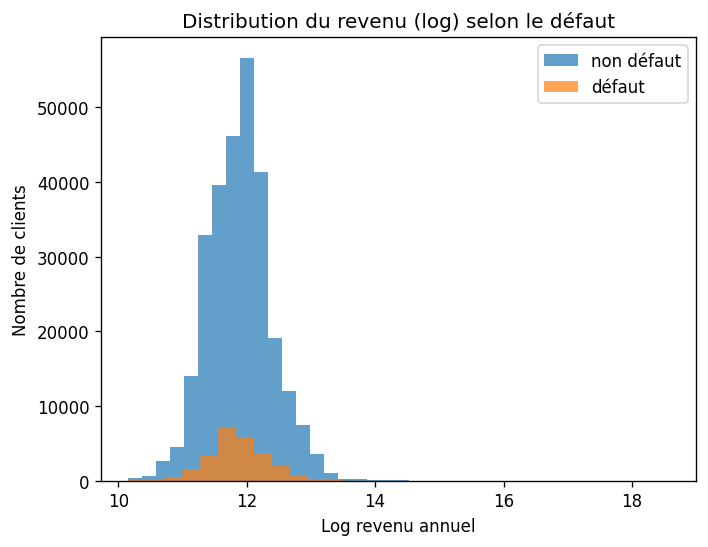

In [12]:
df['LOG_INCOME'] = np.log1p(df['AMT_INCOME_TOTAL'])

plt.hist(df[df['TARGET'] == 0]['LOG_INCOME'], bins = 30, alpha = 0.7, label = 'non défaut')
plt.hist(df[df['TARGET'] == 1]['LOG_INCOME'], bins = 30, alpha = 0.7, label = 'défaut')
plt.title("Distribution du revenu (log) selon le défaut")
plt.xlabel('Log revenu annuel')
plt.ylabel('Nombre de clients')
plt.legend()
plt.show()

Le risque de défaut est attendu plus élevé pour les clients à faibles revenus, en raison d’une capacité de remboursement limitée.
Toutefois, des revenus élevés ne garantissent pas l’absence de risque, notamment lorsque les montants empruntés et les mensualités augmentent.
La relation entre revenu et risque est donc non linéaire et s’exprime plutôt par des effets de seuil.

La visualisation du risque par revenu est réalisée par tranches afin de calculer un taux de défaut comparable entre segments, indépendamment du volume de clients.

In [13]:
# On découpe le dataset en 5 tranches équivalentes en fonction de la colonne AMT INCOME TOTAL

df['LOG_INCOME_BIN'] = pd.qcut(df['LOG_INCOME'], q=5)

In [14]:
# Calcul du taux de défaut par tranche

defaut_rate_by_income = ( df.groupby('LOG_INCOME_BIN')['TARGET'].mean().reset_index() )

<cell-28>:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.


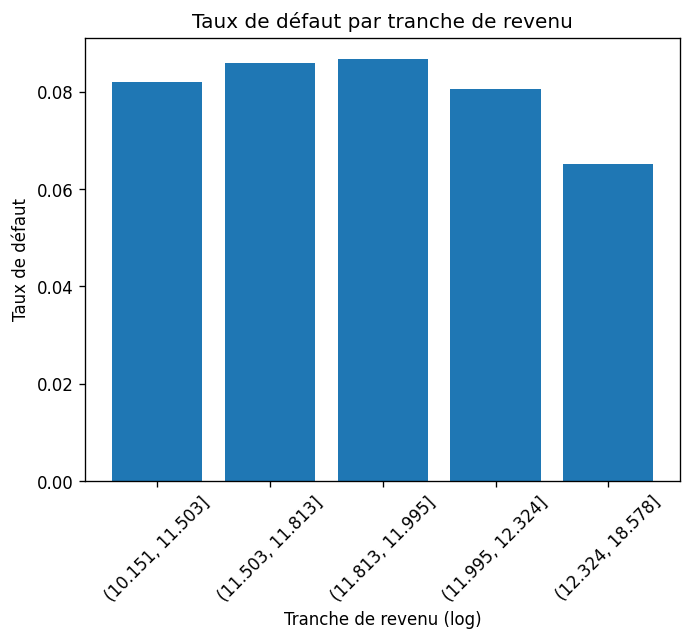

In [15]:
plt.bar(
    defaut_rate_by_income['LOG_INCOME_BIN'].astype(str),
    defaut_rate_by_income['TARGET']
)

plt.title('Taux de défaut par tranche de revenu')
plt.xlabel('Tranche de revenu (log)')
plt.ylabel('Taux de défaut')
plt.xticks(rotation=45)
plt.show()

Le revenu, pris isolément, ne semble pas fortement discriminant pour expliquer le risque de défaut sur la majorité du portefeuille, les trois premières tranches présentant des taux de défaut proches.
En revanche, les clients appartenant à la tranche de revenus la plus élevée présentent un risque significativement plus faible, ce qui suggère un effet protecteur des très hauts revenus.

# Construction d'indicateurs

Un ratio de remboursement élevé relativement au revenu peut signaler une capacité financière plus contrainte. On explorera la relation avec le défaut, sans supposer à l'avance qu'elle suit des seuils précis ou qu'elle est causale.

Nous construisons ici un **proxy annuité/revenu**, faute de connaître la charge de l'ensemble des dettes de chaque client. Le nom technique `DTI_approx` est conservé dans le code par continuité avec le projet initial, mais il ne s'agit pas d'un véritable ratio d'endettement global.

In [16]:
# Construction d'un DTI approximatif (Nous avons uniquement des infos sur le crédit immobilier)

df['DTI_approx'] = df['AMT_ANNUITY'] / ( df['AMT_INCOME_TOTAL'] + 1)

Le ratio `AMT_ANNUITY / AMT_INCOME_TOTAL` est un **proxy de charge d'annuité par rapport au revenu**, et non un DTI complet : toutes les autres dettes du client ne sont pas connues. L'ajout de 1 au dénominateur évite une division par zéro.

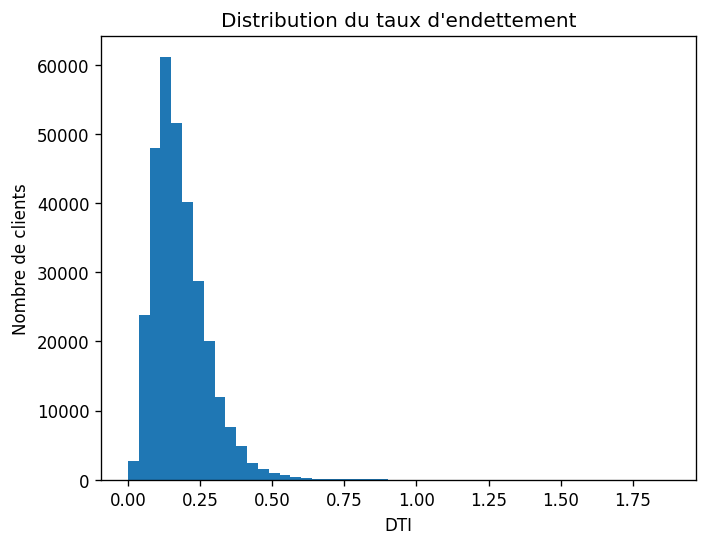

In [17]:
plt.hist(df['DTI_approx'], bins = 50)
plt.title("Distribution du ratio annuité/revenu")
plt.xlabel("Ratio annuité/revenu")
plt.ylabel("Nombre de clients")
plt.show()

In [18]:
# Ce filtrage du 1 % supérieur sert UNIQUEMENT à rendre les graphiques d'EDA lisibles.
# Pour la modélisation, TOUS les demandeurs seront conservés, afin d'éviter
# qu'un filtrage global (calculé avant la séparation des jeux) biaise l'évaluation.
dti_cap_eda = df['DTI_approx'].quantile(0.99)
df_dti = df.loc[df['DTI_approx'] <= dti_cap_eda].copy()

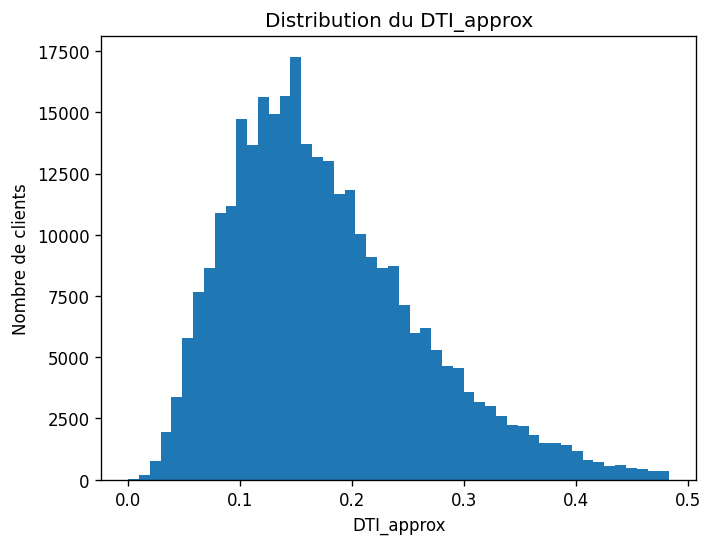

In [19]:
plt.hist(df_dti['DTI_approx'], bins = 50)
plt.title("Distribution du ratio annuité/revenu")
plt.xlabel("DTI_approx")
plt.ylabel("Nombre de clients")
plt.show()

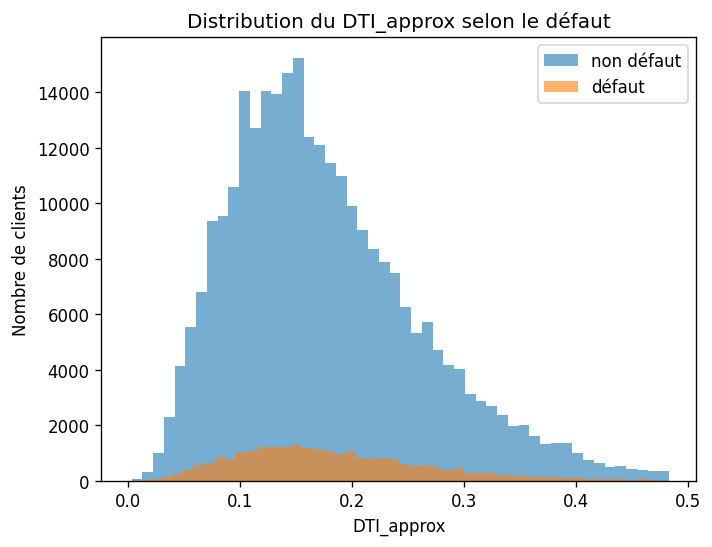

In [20]:
plt.hist(df_dti[df_dti['TARGET']==0]['DTI_approx'], bins = 50, alpha = 0.6, label = 'non défaut')
plt.hist(df_dti[df_dti['TARGET']==1]['DTI_approx'], bins = 50, alpha = 0.6, label = 'défaut')

plt.title('Distribution du DTI_approx selon le défaut')
plt.xlabel('DTI_approx')
plt.ylabel('Nombre de clients')
plt.legend()
plt.show()

In [21]:
# Découpage descriptif du ratio annuité/revenu en tranches

bins = [0, 0.13, 0.20, 0.30, 1]
labels = ["0-13%", "13-20%", "20-30%", "30%+"]
df_dti['DTI_BIN'] = pd.cut(df_dti['DTI_approx'], bins = bins, labels = labels)
default_rate_by_dti = (df_dti.groupby('DTI_BIN')['TARGET'].mean())

<cell-40>:6: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.


In [22]:
result = df_dti.groupby('DTI_BIN').agg(nb_clients = ('TARGET', 'count'), taux_defaut = ('TARGET', 'mean'))
result

<cell-41>:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.


,nb_clients,taux_defaut
DTI_BIN,,
0-13%,100449,0.073948
13-20%,101992,0.082144
20-30%,73742,0.087643
30%+,28241,0.082221


Sur les tranches représentées, le taux de défaut varie selon le ratio annuité/revenu. Les catégories aux effectifs limités sont à interpréter avec prudence ; il ne s'agit pas d'une relation causale.

In [23]:
# Dans cette partie, nous allons analyser le comportement du taux de défaut en combinant 3 variables : AGE, AMT_TOTAL_INCOME & DTI_approx

df_dti['AGE'] = -df_dti['DAYS_BIRTH'] / 365

age_bins = [18, 30, 40, 60, 100]
df_dti['AGE_BIN'] = pd.cut(df_dti['AGE'], bins = age_bins)

income_bins = [0, 50000, 100000, 200000, 750000]
df_dti['INCOME_BIN'] = pd.cut(df_dti['AMT_INCOME_TOTAL'], bins = income_bins)

## Heatmap de 2 variables combinées parmi les 3 en face du taux de défaut 

<cell-45>:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.


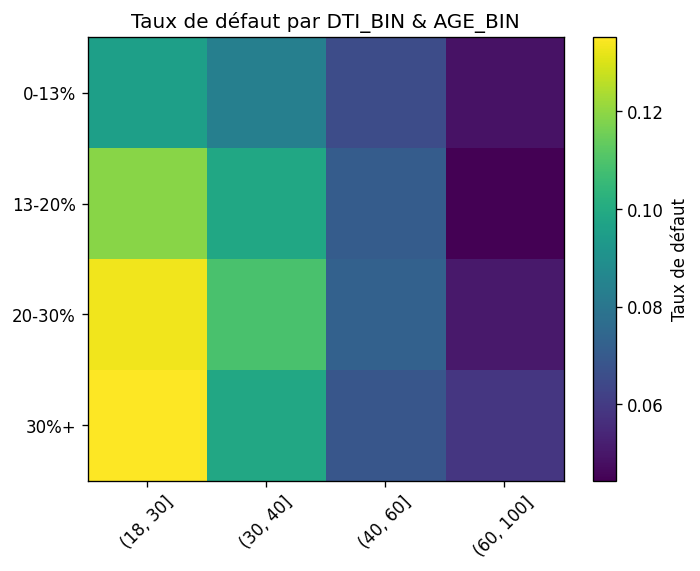

In [24]:
result = df_dti.groupby(['DTI_BIN', 'AGE_BIN'])['TARGET'].mean().unstack()

plt.imshow(result, aspect = 'auto')
plt.colorbar(label='Taux de défaut')
plt.xticks(range(len(result.columns)), result.columns, rotation = 45)
plt.yticks(range(len(result.index)), result.index)
plt.title('Taux de défaut par DTI_BIN & AGE_BIN')
plt.show()

<cell-46>:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.


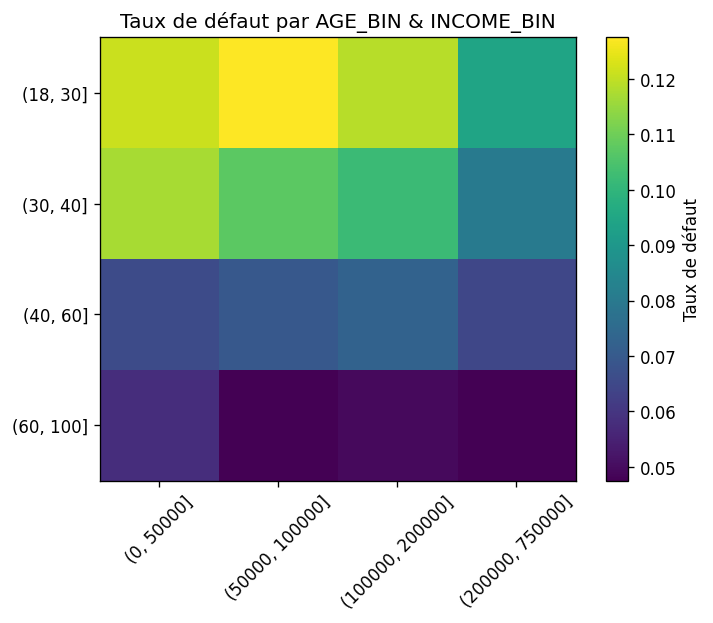

In [25]:
result = df_dti.groupby( ['AGE_BIN', 'INCOME_BIN'] )['TARGET'].mean().unstack()

plt.imshow(result, aspect = 'auto')
plt.colorbar(label='Taux de défaut')
plt.xticks(range(len(result.columns)), result.columns, rotation = 45)
plt.yticks(range(len(result.index)), result.index)
plt.title('Taux de défaut par AGE_BIN & INCOME_BIN')
plt.show()

<cell-47>:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.


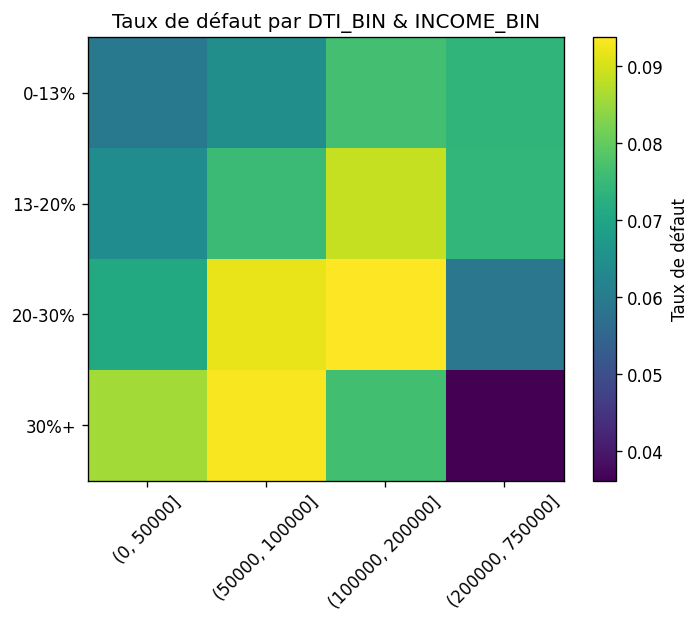

In [26]:
result = df_dti.groupby( ['DTI_BIN', 'INCOME_BIN'] )['TARGET'].mean().unstack()

plt.imshow(result, aspect = 'auto')
plt.colorbar(label='Taux de défaut')
plt.xticks(range(len(result.columns)), result.columns, rotation = 45)
plt.yticks(range(len(result.index)), result.index)
plt.title('Taux de défaut par DTI_BIN & INCOME_BIN')
plt.show()

Les croisements âge / revenu / charge d'annuité font ressortir des différences de taux observés entre segments. Ces constats sont descriptifs, parfois sensibles aux effectifs et ne suffisent pas à établir des relations causales ou une règle d'octroi.

## Heatmap globale pour une vue d'ensemble

<cell-50>:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.


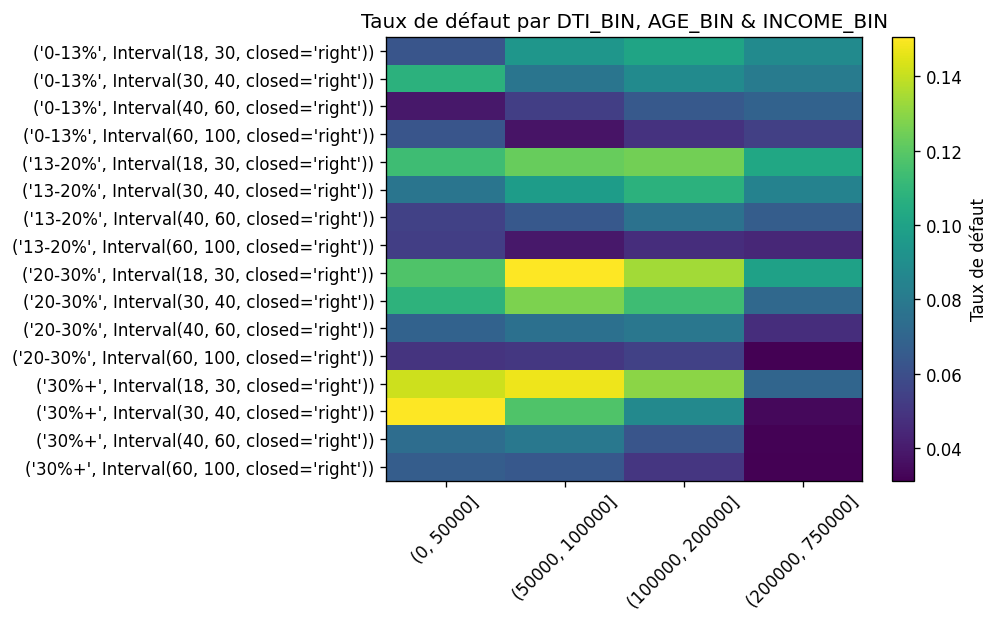

In [27]:
result = df_dti.groupby( ['DTI_BIN', 'AGE_BIN', 'INCOME_BIN'] )['TARGET'].mean().unstack()

plt.imshow(result, aspect = 'auto')
plt.colorbar(label='Taux de défaut')
plt.xticks(range(len(result.columns)), result.columns, rotation = 45)
plt.yticks(range(len(result.index)), result.index)
plt.title('Taux de défaut par DTI_BIN, AGE_BIN & INCOME_BIN')
plt.show()

# MODELISATION : Machine Learning

Les variables de capacité financière telles que le taux d’endettement, l'âge et le revenu sont incluses en priorité, car elles présentent un signal plus direct sur le risque de défaut d'un point de vue business.

In [28]:
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score

# On conserve les mêmes clients dans chaque ensemble à chaque étape.
# Le jeu de test final n'est pas utilisé pour choisir les variables ni la pondération.
assert df['SK_ID_CURR'].is_unique, "Un identifiant client doit être unique dans application_train.csv"
identifiants = df['SK_ID_CURR'].to_numpy()
cibles = df['TARGET'].to_numpy()
ids_train_val, ids_test = train_test_split(
    identifiants, test_size=0.20, stratify=cibles, random_state=42
)
cible_par_client = df.set_index('SK_ID_CURR')['TARGET']
ids_train, ids_validation = train_test_split(
    ids_train_val,
    test_size=0.25,  # 25 % de 80 % = 20 % du jeu complet
    stratify=cible_par_client.loc[ids_train_val].to_numpy(),
    random_state=42,
)
assert set(ids_train).isdisjoint(ids_validation)
assert set(ids_train_val).isdisjoint(ids_test)

resultats_validation = []

def construire_modele(class_weight=None):
    """Imputation et standardisation apprises UNIQUEMENT sur les lignes d'entraînement."""
    return Pipeline([
        ('imputation', SimpleImputer(strategy='median')),
        ('standardisation', StandardScaler()),
        ('regression_logistique', LogisticRegression(max_iter=500, class_weight=class_weight, solver='lbfgs')),
    ])

def evaluer_modele(table_clients, etape, class_weight=None):
    """Comparer les variables sur un jeu de validation fixe (et jamais sur le test)."""
    variables = table_clients.drop(columns=['SK_ID_CURR', 'TARGET']).columns.tolist()
    X = table_clients[variables]
    y = table_clients['TARGET']
    masque_train = table_clients['SK_ID_CURR'].isin(ids_train)
    masque_validation = table_clients['SK_ID_CURR'].isin(ids_validation)

    assert masque_train.sum() == len(ids_train)
    assert masque_validation.sum() == len(ids_validation)
    modele = construire_modele(class_weight=class_weight)
    modele.fit(X.loc[masque_train], y.loc[masque_train])
    proba_validation = modele.predict_proba(X.loc[masque_validation])[:, 1]
    auc = roc_auc_score(y.loc[masque_validation], proba_validation)
    resultats_validation.append({
        'Étape': etape,
        'Pondération': class_weight or 'Aucune',
        'Nb variables': len(variables),
        'ROC-AUC validation': auc,
    })
    print(f'{etape} | ROC-AUC validation : {auc:.4f}')
    return modele, auc, variables

def afficher_coefficients(modele, noms_variables):
    """Coefficients comparables car estimés sur variables standardisées."""
    coefficients = modele.named_steps['regression_logistique'].coef_[0]
    return (pd.DataFrame({'Variable': noms_variables, 'Coefficient': coefficients})
              .sort_values('Coefficient', ascending=False))

print(f'Entraînement : {len(ids_train):,} clients ; '
      f'validation : {len(ids_validation):,} ; test final : {len(ids_test):,}')


Entraînement : 184,506 clients ; validation : 61,502 ; test final : 61,503


In [29]:
# Modèle de départ : variables financières faciles à interpréter
features = ['AGE', 'LOG_INCOME', 'DTI_approx']
data = df[['SK_ID_CURR'] + features + ['TARGET']].copy()


In [30]:
# Réutilisation de la séparation fixe définie dans la cellule précédente.
# Aucun nouveau train_test_split ne sera réalisé lors de l'ajout de variables.
assert data['SK_ID_CURR'].is_unique


In [31]:
# SimpleImputer + StandardScaler + LogisticRegression sont inclus dans
# le Pipeline et sont ajustés exclusivement sur l'entraînement.


In [32]:
model, roc_auc_validation, variables_modele = evaluer_modele(
    data, 'Variables financières'
)


Variables financières | ROC-AUC validation : 0.5888


In [33]:
afficher_coefficients(model, variables_modele)


,Variable,Coefficient
2,DTI_approx,0.042224
1,LOG_INCOME,-0.083512
0,AGE,-0.310268


In [34]:
print(f'ROC-AUC sur la validation (variables financières) : {roc_auc_validation:.4f}')


ROC-AUC sur la validation (variables financières) : 0.5888


Le premier modèle s'appuie sur l'âge, le revenu et le proxy de charge d'annuité. Ses performances de validation sont comparées aux modèles suivants **sur exactement les mêmes demandeurs**. Les modèles utilisent la totalité du portefeuille de départ (pas de filtrage du dernier centile de DTI en modélisation).

# Ajout de données supplémentaires

La table bureau contient l'historique des crédits accordés aux clients et les potentiels défauts associés. Prenons en compte ces données pour améliorer notre modèle de base.

In [35]:
# Lecture des seules colonnes utilisées : plus économe en mémoire.
bureau = pd.read_csv('bureau.csv', usecols=['SK_ID_CURR', 'CREDIT_ACTIVE', 'CREDIT_DAY_OVERDUE'])
bureau.head()

,SK_ID_CURR,CREDIT_ACTIVE,CREDIT_DAY_OVERDUE
0,215354,Closed,0
1,215354,Active,0
2,215354,Active,0
3,215354,Active,0
4,215354,Active,0


In [36]:
# Collectons des données pertinentes à partir de la table bureau en créant des indicateurs

nb_credits = bureau.groupby('SK_ID_CURR').size().rename('BUREAU_NB_CREDITS')  #Total de crédits enregistrés
nb_active = bureau['CREDIT_ACTIVE'].eq('Active').groupby(bureau['SK_ID_CURR']).sum().rename('BUREAU_NB_ACTIVE') #Nombre de crédits actifs
nb_closed = bureau['CREDIT_ACTIVE'].eq('Closed').groupby(bureau['SK_ID_CURR']).sum().rename('BUREAU_NB_CLOSED') #Nombre de crédits clos
has_overdue = (bureau['CREDIT_DAY_OVERDUE'].gt(0).groupby(bureau['SK_ID_CURR'])
               .max().astype(int).rename('BUREAU_HAS_OVERDUE')) #Au moins un crédit avec un retard > 0 jours
nb_overdue_credits = (bureau['CREDIT_DAY_OVERDUE'].gt(0).groupby(bureau['SK_ID_CURR'])
                      .sum().rename('BUREAU_NB_OVERDUE_CREDITS')) #Nombre de crédits en retard

In [37]:
# Création d'un nouveau dataset à partir des données agrégées du dataset bureau

bureau_features = pd.concat([nb_credits, nb_active, nb_closed, has_overdue, nb_overdue_credits], axis = 1).reset_index()
bureau_features.head()

,SK_ID_CURR,BUREAU_NB_CREDITS,BUREAU_NB_ACTIVE,BUREAU_NB_CLOSED,BUREAU_HAS_OVERDUE,BUREAU_NB_OVERDUE_CREDITS
0,100001,7,3,4,0,0
1,100002,8,2,6,0,0
2,100003,4,1,3,0,0
3,100004,2,0,2,0,0
4,100005,3,2,1,0,0


In [38]:
# Les mêmes clients sont conservés à chaque étape ; on ajoute seulement des variables.
df = df[['SK_ID_CURR'] + features + ['TARGET']].copy()
df = df.merge(bureau_features, on='SK_ID_CURR', how='left', validate='one_to_one')
df.head()


,SK_ID_CURR,AGE,LOG_INCOME,DTI_approx,TARGET,BUREAU_NB_CREDITS,BUREAU_NB_ACTIVE,BUREAU_NB_CLOSED,BUREAU_HAS_OVERDUE,BUREAU_NB_OVERDUE_CREDITS
0,100002,25.9,12.218500,0.121977,1,8.0,2.0,6.0,0.0,0.0
1,100003,45.9,12.506181,0.132216,0,4.0,1.0,3.0,0.0,0.0
2,100004,52.2,11.119898,0.099999,0,2.0,0.0,2.0,0.0,0.0
3,100006,52.1,11.813037,0.219898,0,NaN,NaN,NaN,NaN,NaN
4,100007,54.6,11.707678,0.179961,0,1.0,0.0,1.0,0.0,0.0


In [39]:
# Certains clients peuvent être nouveau. De ce fait, aucun historique n'est disponible et donc des NaN peuvent être présents.
df.isna().sum()

SK_ID_CURR                       0
AGE                              0
LOG_INCOME                       0
DTI_approx                      12
TARGET                           0
BUREAU_NB_CREDITS            44020
BUREAU_NB_ACTIVE             44020
BUREAU_NB_CLOSED             44020
BUREAU_HAS_OVERDUE           44020
BUREAU_NB_OVERDUE_CREDITS    44020
dtype: int64

In [40]:
# Construction d'une variable indiquant si oui ou non, le  client fait parti de l'historique de nos demandes de crédit
df['HAS_BUREAU_HISTORY'] = df['BUREAU_NB_CREDITS'].notna().astype(int)

In [41]:
# Zéro a un sens pour les décomptes en l'absence d'historique bureau.
# Les valeurs manquantes des variables initiales sont imputées par le Pipeline.
bureau_cols = [
    'BUREAU_NB_CREDITS', 'BUREAU_NB_ACTIVE', 'BUREAU_NB_CLOSED',
    'BUREAU_HAS_OVERDUE', 'BUREAU_NB_OVERDUE_CREDITS',
]
df[bureau_cols] = df[bureau_cols].fillna(0)


In [42]:
df.groupby('HAS_BUREAU_HISTORY')['TARGET'].mean()

HAS_BUREAU_HISTORY
0    0.101249
1    0.077301
Name: TARGET, dtype: float64

In [43]:
# Comparaison descriptive des taux de défaut selon la présence d'un historique.
# Ce résultat ne prouve pas de relation causale.
print(df.groupby('HAS_BUREAU_HISTORY')['TARGET'].agg(['mean', 'size']))

                        mean    size
HAS_BUREAU_HISTORY                  
0                   0.101249   44020
1                   0.077301  263491


In [44]:
# Le jeu de validation reste identique : pas de nouvelle séparation.
model, roc_auc_validation, variables_modele = evaluer_modele(
    df, 'Variables financières + bureau'
)


Variables financières + bureau | ROC-AUC validation : 0.6179


In [45]:
# L'imputation et la standardisation ont été apprises sur le train dans le Pipeline.


In [46]:
# Modèle ajusté et évalué par evaluer_modele (cellule précédente).


In [47]:
print(f'ROC-AUC validation (+ bureau) : {roc_auc_validation:.4f}')


ROC-AUC validation (+ bureau) : 0.6179


In [48]:
afficher_coefficients(model, variables_modele)


,Variable,Coefficient
4,BUREAU_NB_ACTIVE,0.330737
2,DTI_approx,0.060642
7,BUREAU_NB_OVERDUE_CREDITS,0.060021
6,BUREAU_HAS_OVERDUE,0.003480
3,BUREAU_NB_CREDITS,-0.011767
1,LOG_INCOME,-0.095041
8,HAS_BUREAU_HISTORY,-0.150085
5,BUREAU_NB_CLOSED,-0.208586
0,AGE,-0.295230


In [49]:
# Colonnes nécessaires à l'agrégation des anciennes demandes.
previous_appli = pd.read_csv('previous_application.csv', usecols=['SK_ID_CURR', 'NAME_CONTRACT_STATUS', 'AMT_APPLICATION'])
previous_appli.head()

,SK_ID_CURR,AMT_APPLICATION,NAME_CONTRACT_STATUS
0,271877,17145.0,Approved
1,108129,607500.0,Approved
2,122040,112500.0,Approved
3,176158,450000.0,Approved
4,202054,337500.0,Refused


Dans un premier temps, nous allons nous concentrer sur 3 nouvelles variables. 
Nous allons travailler avec NB_PREV_APP, NB_REFUSED et AVG_AMT_APPLICATION. Ces 3 variables contiennent les informations suivantes : Nombre d'anciennes demandes, Nombre de demandes refusées et le montant moyen demandé. Nous adoptons cette stratégie pour garder de la clarté dans le choix de nos variables et leur importance dans notre modèle d'attribution.

In [50]:
# Extraction des 3 variables qui nous intéressent

nb_prev_app = previous_appli.groupby('SK_ID_CURR').size().rename('NB_PREV_APP') # Nombre total de demandes ( liste des SK_ID_CURR )
nb_refused = previous_appli['NAME_CONTRACT_STATUS'].eq('Refused').groupby(previous_appli['SK_ID_CURR']).sum().rename('NB_REFUSED') # Nombre de refus
avg_amt_app = previous_appli.groupby('SK_ID_CURR')['AMT_APPLICATION'].mean().rename('AVG_AMT_APPLICATION') # Montant moyen demandé

prev_features = pd.concat( [nb_prev_app, nb_refused, avg_amt_app], axis = 1 ).reset_index()
prev_features.head()

,SK_ID_CURR,NB_PREV_APP,NB_REFUSED,AVG_AMT_APPLICATION
0,100001,1,0,24835.50
1,100002,1,0,179055.00
2,100003,3,0,435436.50
3,100004,1,0,24282.00
4,100005,2,0,22308.75


In [51]:
df = df.merge(prev_features, on='SK_ID_CURR', how='left', validate='one_to_one')
df.head()


,SK_ID_CURR,AGE,LOG_INCOME,DTI_approx,TARGET,BUREAU_NB_CREDITS,BUREAU_NB_ACTIVE,BUREAU_NB_CLOSED,BUREAU_HAS_OVERDUE,BUREAU_NB_OVERDUE_CREDITS,HAS_BUREAU_HISTORY,NB_PREV_APP,NB_REFUSED,AVG_AMT_APPLICATION
0,100002,25.9,12.218500,0.121977,1,8.0,2.0,6.0,0.0,0.0,1,1.0,0.0,179055.00
1,100003,45.9,12.506181,0.132216,0,4.0,1.0,3.0,0.0,0.0,1,3.0,0.0,435436.50
2,100004,52.2,11.119898,0.099999,0,2.0,0.0,2.0,0.0,0.0,1,1.0,0.0,24282.00
3,100006,52.1,11.813037,0.219898,0,0.0,0.0,0.0,0.0,0.0,0,9.0,1.0,272203.26
4,100007,54.6,11.707678,0.179961,0,1.0,0.0,1.0,0.0,0.0,1,6.0,0.0,150530.25


In [52]:
df.isna().sum()

SK_ID_CURR                       0
AGE                              0
LOG_INCOME                       0
DTI_approx                      12
TARGET                           0
BUREAU_NB_CREDITS                0
BUREAU_NB_ACTIVE                 0
BUREAU_NB_CLOSED                 0
BUREAU_HAS_OVERDUE               0
BUREAU_NB_OVERDUE_CREDITS        0
HAS_BUREAU_HISTORY               0
NB_PREV_APP                  16454
NB_REFUSED                   16454
AVG_AMT_APPLICATION          16454
dtype: int64

In [53]:
df['HAS_PREV_HISTORY'] = df['NB_PREV_APP'].notna().astype(int)
# Absence d'historique = aucun événement observé pour les décomptes.
# Le montant moyen reste manquant s'il n'existe aucune demande :
# l'imputation médiane est apprise uniquement sur l'entraînement.
df[['NB_PREV_APP', 'NB_REFUSED']] = df[['NB_PREV_APP', 'NB_REFUSED']].fillna(0)


In [54]:
model, roc_auc_validation, variables_modele = evaluer_modele(
    df, 'Variables financières + bureau + demandes précédentes'
)


Variables financières + bureau + demandes précédentes | ROC-AUC validation : 0.6379


In [55]:
# La standardisation de la validation utilise le scaler ajusté sur l'entraînement.


In [56]:
# Modèle ajusté et évalué par evaluer_modele (cellule précédente).


In [57]:
afficher_coefficients(model, variables_modele)


,Variable,Coefficient
4,BUREAU_NB_ACTIVE,0.309552
10,NB_REFUSED,0.238067
2,DTI_approx,0.070369
12,HAS_PREV_HISTORY,0.062163
7,BUREAU_NB_OVERDUE_CREDITS,0.061561
6,BUREAU_HAS_OVERDUE,-0.001258
3,BUREAU_NB_CREDITS,-0.020245
1,LOG_INCOME,-0.072916
11,AVG_AMT_APPLICATION,-0.083076
9,NB_PREV_APP,-0.095230


In [58]:
print(f'ROC-AUC validation (+ demandes précédentes) : {roc_auc_validation:.4f}')


ROC-AUC validation (+ demandes précédentes) : 0.6379


In [59]:
# Environ 13,6 M de lignes : ne charger que les trois colonnes nécessaires.
install_pay = pd.read_csv(
    'installments_payments.csv',
    usecols=['SK_ID_CURR', 'DAYS_ENTRY_PAYMENT', 'DAYS_INSTALMENT'],
    dtype={'SK_ID_CURR': 'int32', 'DAYS_ENTRY_PAYMENT': 'float32', 'DAYS_INSTALMENT': 'int32'},
)
print(f'Paiements lus : {len(install_pay):,} lignes')
install_pay.head()

Paiements lus : 13,605,401 lignes


,SK_ID_CURR,DAYS_INSTALMENT,DAYS_ENTRY_PAYMENT
0,161674,-1180,-1187.0
1,151639,-2156,-2156.0
2,193053,-63,-63.0
3,199697,-2418,-2426.0
4,167756,-1383,-1366.0


In [60]:
# On considère les remboursements avec une date de paiement observée.
# Une date de paiement absente ne vaut pas "zéro jour de retard".
install_pay = install_pay.dropna(subset=['DAYS_ENTRY_PAYMENT', 'DAYS_INSTALMENT']).copy()
install_pay['DELAY'] = install_pay['DAYS_ENTRY_PAYMENT'] - install_pay['DAYS_INSTALMENT']
group_id = install_pay['SK_ID_CURR']
retard = install_pay['DELAY'].gt(0)
nb_late = retard.groupby(group_id).sum().rename('NB_LATE_PAYMENTS')
avg_delay = install_pay['DELAY'].clip(lower=0).groupby(group_id).mean().rename('AVG_DELAY')
late_ratio = retard.groupby(group_id).mean().rename('LATE_PAYMENT_RATIO')
del install_pay


In [61]:
install_features = pd.concat([nb_late, avg_delay, late_ratio], axis=1).reset_index()
df = df.merge(install_features, on='SK_ID_CURR', how='left', validate='one_to_one')
df.head()


,SK_ID_CURR,AGE,LOG_INCOME,DTI_approx,TARGET,BUREAU_NB_CREDITS,BUREAU_NB_ACTIVE,...,NB_PREV_APP,NB_REFUSED,AVG_AMT_APPLICATION,HAS_PREV_HISTORY,NB_LATE_PAYMENTS,AVG_DELAY,LATE_PAYMENT_RATIO
0,100002,25.9,12.218500,0.121977,1,8.0,2.0,...,1.0,0.0,179055.00,1,0.0,0.000000,0.000000
1,100003,45.9,12.506181,0.132216,0,4.0,1.0,...,3.0,0.0,435436.50,1,0.0,0.000000,0.000000
2,100004,52.2,11.119898,0.099999,0,2.0,0.0,...,1.0,0.0,24282.00,1,0.0,0.000000,0.000000
3,100006,52.1,11.813037,0.219898,0,0.0,0.0,...,9.0,1.0,272203.26,1,0.0,0.000000,0.000000
4,100007,54.6,11.707678,0.179961,0,1.0,0.0,...,6.0,0.0,150530.25,1,16.0,0.954545,0.242424


In [62]:
df.isna().sum()

SK_ID_CURR                       0
AGE                              0
LOG_INCOME                       0
DTI_approx                      12
TARGET                           0
BUREAU_NB_CREDITS                0
BUREAU_NB_ACTIVE                 0
BUREAU_NB_CLOSED                 0
BUREAU_HAS_OVERDUE               0
BUREAU_NB_OVERDUE_CREDITS        0
HAS_BUREAU_HISTORY               0
NB_PREV_APP                      0
NB_REFUSED                       0
AVG_AMT_APPLICATION          16454
HAS_PREV_HISTORY                 0
NB_LATE_PAYMENTS             15876
AVG_DELAY                    15876
LATE_PAYMENT_RATIO           15876
dtype: int64

In [63]:
df['HAS_INSTALL_HISTORY'] = df['NB_LATE_PAYMENTS'].notna().astype(int)
# Les décomptes/ratios valent zéro en l'absence d'historique.
# Les autres valeurs manquantes sont imputées dans le Pipeline.
df[['NB_LATE_PAYMENTS', 'LATE_PAYMENT_RATIO']] = (
    df[['NB_LATE_PAYMENTS', 'LATE_PAYMENT_RATIO']].fillna(0)
)


In [64]:
model, roc_auc_validation, variables_modele = evaluer_modele(
    df, 'Variables financières + tous les historiques'
)
roc_auc_standard = roc_auc_validation


Variables financières + tous les historiques | ROC-AUC validation : 0.6506


In [65]:
# Toujours le même jeu de validation, sans réajustement sur ses observations.


In [66]:
# Modèle ajusté et évalué par evaluer_modele (cellule précédente).


In [67]:
afficher_coefficients(model, variables_modele)


,Variable,Coefficient
4,BUREAU_NB_ACTIVE,0.304536
10,NB_REFUSED,0.220102
15,LATE_PAYMENT_RATIO,0.213768
2,DTI_approx,0.070183
7,BUREAU_NB_OVERDUE_CREDITS,0.063473
12,HAS_PREV_HISTORY,0.036191
16,HAS_INSTALL_HISTORY,-0.004003
6,BUREAU_HAS_OVERDUE,-0.008780
14,AVG_DELAY,-0.012567
3,BUREAU_NB_CREDITS,-0.012596


In [68]:
print(f'ROC-AUC validation (modèle complet) : {roc_auc_standard:.4f}')


ROC-AUC validation (modèle complet) : 0.6506


## Pondération des classes et évaluation finale

Comparaison **sans** et **avec** `class_weight='balanced'` sur la même validation. Le classement de la ROC-AUC détermine la configuration retenue. L'**Average Precision** complète l'analyse des classes rares (sa référence de base est la prévalence de la classe positive).

Le test final est conservé à part et n'intervient pas dans le choix de la pondération. L'ensemble *train + validation* sert au réentraînement final, avant une **évaluation unique** sur les 20 % de test.

In [69]:
# Test explicite de la pondération, sur les mêmes variables et la même validation.
modele_equilibre, roc_auc_equilibre, _ = evaluer_modele(
    df, 'Variables financières + tous les historiques', class_weight='balanced'
)

# Récapitulatif de toutes les étapes : comparer uniquement ces scores de validation.
comparaison = pd.DataFrame(resultats_validation)
comparaison

Variables financières + tous les historiques | ROC-AUC validation : 0.6518


,Étape,Pondération,Nb variables,ROC-AUC validation
0,Variables financières,Aucune,3,0.588766
1,Variables financières + bureau,Aucune,9,0.617899
2,Variables financières + bureau + demandes précédentes,Aucune,13,0.637878
3,Variables financières + tous les historiques,Aucune,17,0.650603
4,Variables financières + tous les historiques,balanced,17,0.651817


In [70]:
# Choix de la pondération uniquement à partir de la validation.
# En cas d'égalité, préférence pour le modèle sans pondération.
pond_finale = 'balanced' if roc_auc_equilibre > roc_auc_standard else None
print('Pondération retenue sur la validation :', pond_finale or 'Aucune')

# Ajustement final sur entraînement + validation, puis évaluation UNE SEULE FOIS sur le test.
variables_finales = df.drop(columns=['SK_ID_CURR', 'TARGET']).columns.tolist()
X_final = df[variables_finales]
y_final = df['TARGET']
masque_train_val = df['SK_ID_CURR'].isin(ids_train_val)
masque_test = df['SK_ID_CURR'].isin(ids_test)
assert masque_train_val.sum() == len(ids_train_val)
assert masque_test.sum() == len(ids_test)

modele_final = construire_modele(class_weight=pond_finale)
modele_final.fit(X_final.loc[masque_train_val], y_final.loc[masque_train_val])
proba_test_final = modele_final.predict_proba(X_final.loc[masque_test])[:, 1]
auc_test_final = roc_auc_score(y_final.loc[masque_test], proba_test_final)
ap_test_final = average_precision_score(y_final.loc[masque_test], proba_test_final)
prevalence_test = y_final.loc[masque_test].mean()

print(f'ROC-AUC TEST FINAL : {auc_test_final:.4f}')
print(f'Average precision test : {ap_test_final:.4f} (prévalence défaut : {prevalence_test:.4f})')
afficher_coefficients(modele_final, variables_finales)

Pondération retenue sur la validation : balanced
ROC-AUC TEST FINAL : 0.6508
Average precision test : 0.1450 (prévalence défaut : 0.0807)


,Variable,Coefficient
3,BUREAU_NB_CREDITS,0.939113
10,NB_REFUSED,0.253225
15,LATE_PAYMENT_RATIO,0.231177
7,BUREAU_NB_OVERDUE_CREDITS,0.068842
2,DTI_approx,0.066519
12,HAS_PREV_HISTORY,0.027124
16,HAS_INSTALL_HISTORY,0.010969
14,AVG_DELAY,-0.013176
6,BUREAU_HAS_OVERDUE,-0.014017
13,NB_LATE_PAYMENTS,-0.039397


Rapport de classification au seuil 0,50 :
              precision    recall  f1-score   support

           0       0.95      0.63      0.76     56538
           1       0.12      0.59      0.20      4965

    accuracy                           0.63     61503
   macro avg       0.53      0.61      0.48     61503
weighted avg       0.88      0.63      0.71     61503

Matrice de confusion au seuil 0,50 :
[[35745 20793]
 [ 2058  2907]]


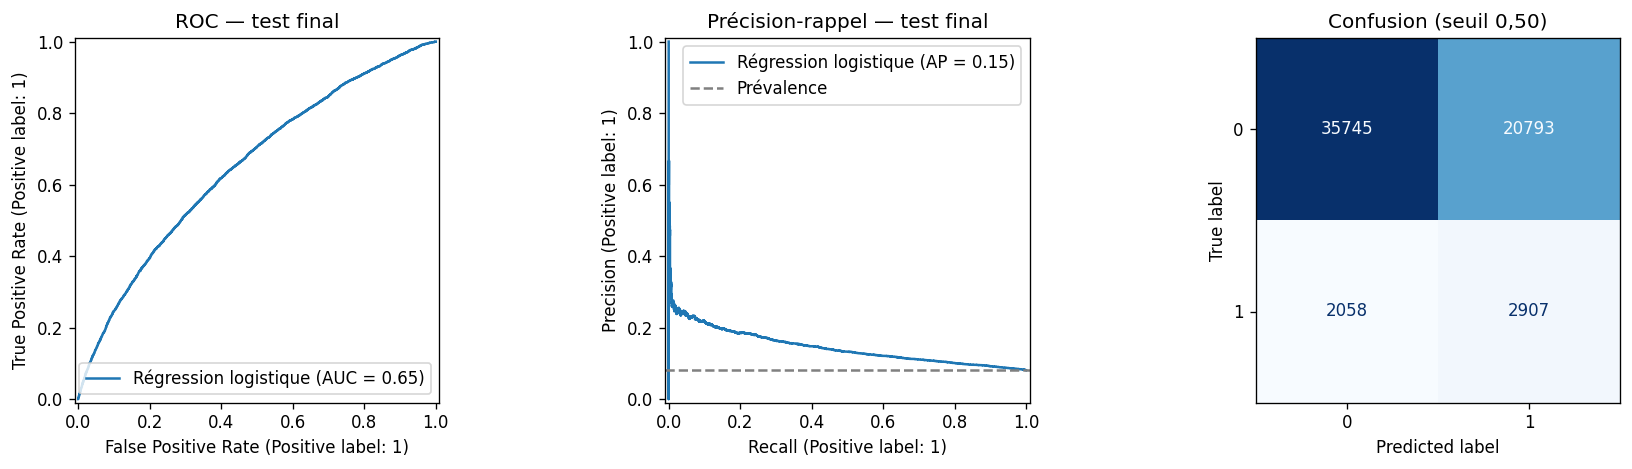

In [71]:
from sklearn.metrics import (roc_curve, precision_recall_curve, confusion_matrix,
                             ConfusionMatrixDisplay, RocCurveDisplay,
                             PrecisionRecallDisplay, classification_report)

# Résultats sur l'unique jeu de test final. Le seuil 0,50 est uniquement illustratif.
y_test_final = y_final.loc[masque_test]
print('Rapport de classification au seuil 0,50 :')
print(classification_report(y_test_final, (proba_test_final >= 0.50).astype(int), zero_division=0))
print('Matrice de confusion au seuil 0,50 :')
print(confusion_matrix(y_test_final, (proba_test_final >= 0.50).astype(int)))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
RocCurveDisplay.from_predictions(y_test_final, proba_test_final, ax=axes[0], name='Régression logistique')
axes[0].set_title('ROC — test final')
PrecisionRecallDisplay.from_predictions(y_test_final, proba_test_final, ax=axes[1], name='Régression logistique')
axes[1].axhline(prevalence_test, linestyle='--', color='grey', label='Prévalence')
axes[1].legend()
axes[1].set_title('Précision-rappel — test final')
ConfusionMatrixDisplay.from_predictions(y_test_final, proba_test_final >= 0.50, ax=axes[2], cmap='Blues', colorbar=False)
axes[2].set_title('Confusion (seuil 0,50)')
fig.tight_layout()
plt.show()

## Résultats vérifiés sur le dataset Home Credit fourni

Les quatre fichiers CSV du jeu de données ont été utilisés pour **exécuter intégralement** ce notebook. La comparaison utilise un **ensemble de validation constant** :

| Variables du modèle (régression logistique) | ROC-AUC sur validation |
|---|---:|
| Âge, log-revenu, ratio annuité/revenu | **0,5888** |
| + Historique `bureau` | **0,6179** |
| + Demandes précédentes | **0,6379** |
| + Paiements observés | **0,6506** |
| + Pondération `class_weight="balanced"` | **0,6518** |

La pondération est retenue grâce à une amélioration **très faible** de la ROC-AUC sur validation (environ +0,0012) : cet écart ne doit pas être interprété comme une supériorité statistiquement établie.

**Évaluation unique sur le jeu de test final (61 503 clients) :**

- **ROC-AUC : 0,6508**.
- **Average Precision : 0,1450**, pour **8,07 %** de cas positifs dans le test.
- Au **seuil arbitraire de 0,50** : rappel des défauts **0,59**, précision pour la classe défaut **0,12**. Ces valeurs montrent notamment que de nombreux clients sans défaut seraient considérés à risque à ce seuil.

**Interprétation :** l'ajout progressif de variables comportementales améliore la discrimination par rapport aux seules données financières, mais la performance finale reste **modeste**. Ce prototype pédagogique n'est **pas adapté tel quel à une décision réelle d'octroi de crédit**.


### Interprétation et limites

- La comparaison **à jeu de validation constant** permet de mesurer l'effet d'un enrichissement progressif des variables ; elle ne constitue pas une preuve causale.
- La pondération des classes est réellement testée. Le choix sur la ROC-AUC ne garantit pas un meilleur score en précision/rappel ; un seuil et des coûts d'erreur métier resteraient à définir.
- Le **test final**, évalué une seule fois après sélection, sert à estimer la capacité de généralisation hors échantillon. Les résultats ne doivent pas être présentés comme des performances en production.
- Un **ratio annuité/revenu** ne mesure pas toutes les dettes et ne constitue pas un DTI bancaire complet.
- Les agrégats de paiements utilisent les **paiements avec une date observée** : ils ne mesurent pas les non-paiements et doivent être interprétés avec cette limite.
- Avant un déploiement réel : vérifier que chaque événement des tables historiques précède bien la demande étudiée, contrôler la fuite temporelle, la calibration, la robustesse, l'équité et le cadre réglementaire applicable.
